# SUN RGB-D: 2D boxes, 3D boxes, segmentation

Reads [SUN RGB-D](https://rgbd.cs.princeton.edu/)'s own v2 global metadata (`SUNRGBDMeta2DBB_v2.mat` /
`SUNRGBDMeta3DBB_v2.mat`: per-image `Rtilt`/`K` calibration, matched 2D + 3D box ground truth) and each scene's raw
`annotation2Dfinal/index.json` (per-object 2D segmentation polygons) directly with `scipy`/`json` -- no MATLAB
extraction step. Needs `INSTALL.MD`'s SUN RGB-D section run first, i.e. `$HABITAT_DATA/sunrgbd/` holding `SUNRGBD/`,
`SUNRGBDMeta2DBB_v2.mat` and `SUNRGBDMeta3DBB_v2.mat`.

In [1]:
import json
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio

SUNRGBD_ROOT = Path("/home/hcrassou/habitat_data/data/sunrgbd")

In [2]:
SUNRGBDMeta = sio.loadmat(SUNRGBD_ROOT / "SUNRGBDMeta3DBB_v2.mat", struct_as_record=False, squeeze_me=True)["SUNRGBDMeta"]
SUNRGBDMeta2DBB = sio.loadmat(SUNRGBD_ROOT / "SUNRGBDMeta2DBB_v2.mat", struct_as_record=False, squeeze_me=True)["SUNRGBDMeta2DBB"]
len(SUNRGBDMeta)

10335

## Calibration, box geometry and ground truth loading

`Rtilt`/`K` and the box corner math follow SUN RGB-D's own coordinate convention (upright-depth: Z up, boxes'
`coeffs` are half-extents along `orientation`/its perpendicular/Z; camera: X right, Y down, Z forward).

In [3]:
def scene_dir(rgbpath: str) -> Path:
    relative = rgbpath[rgbpath.index("SUNRGBD"):].split("/image/")[0]
    return SUNRGBD_ROOT / relative


def rotz(theta: float) -> np.ndarray:
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])


def box3d_corners(centroid: np.ndarray, coeffs: np.ndarray, orientation: np.ndarray) -> np.ndarray:
    """8 corners (upright-depth coords) of a SUN RGB-D 3D box."""
    w, l, h = np.abs(coeffs)
    heading = np.arctan2(orientation[1], orientation[0])
    rot = rotz(heading)
    x = [-l, l, l, -l, -l, l, l, -l]
    y = [w, w, -w, -w, w, w, -w, -w]
    z = [h, h, h, h, -h, -h, -h, -h]
    return (rot @ np.array([x, y, z])).T + centroid


def project_upright_depth_to_image(points: np.ndarray, r_tilt: np.ndarray, k: np.ndarray) -> np.ndarray:
    camera = (points @ r_tilt)[:, [0, 2, 1]]
    camera[:, 1] *= -1
    uv = camera @ k.T
    return uv[:, :2] / uv[:, 2:3]

In [4]:
def as_list(struct_or_array) -> list:
    """squeeze_me=True collapses a 1-object struct array to a scalar mat_struct (no .size/len), and a 0-object
    one to an empty float64 ndarray -- normalize both to a plain list."""
    return list(struct_or_array) if isinstance(struct_or_array, np.ndarray) else [struct_or_array]


def matched_objects(e3, e2):
    """Zips groundtruth3DBB with the groundtruth2DBB entries that have a 3D box, skipping images where the two
    lists don't line up 1:1 by class -- SUN RGB-D's own MATLAB extraction hits the same case and drops the image."""
    boxes_3d = as_list(e3.groundtruth3DBB)
    boxes_2d = [b for b in as_list(e2.groundtruth2DBB) if b.has3dbox]
    if len(boxes_3d) != len(boxes_2d) or any(a.classname != b.classname for a, b in zip(boxes_3d, boxes_2d)):
        return None
    return list(zip(boxes_2d, boxes_3d))


def segmentation_polygons(scene: Path) -> list[tuple[str, np.ndarray]]:
    """Per-object 2D polygons from the scene's raw annotation2Dfinal/index.json (independent of the v2 box metadata,
    so it covers every labelled object, not just the 10 detection classes matched_objects keeps)."""
    annotation = json.loads((scene / "annotation2Dfinal" / "index.json").read_text())
    object_names = annotation["objects"]
    polygons = []
    for polygon in annotation["frames"][0]["polygon"]:
        object_index = polygon["object"]
        if object_index is None or object_index < 0 or len(polygon["x"]) < 3:
            continue
        name = object_names[object_index]["name"] or "unknown"
        points = np.array([polygon["x"], polygon["y"]], dtype=np.float32).T
        polygons.append((name, points))
    return polygons

## Drawing helpers

In [5]:
_PALETTE = [(230, 25, 75), (60, 180, 75), (255, 225, 25), (0, 130, 200), (245, 130, 48),
            (145, 30, 180), (70, 240, 240), (240, 50, 230), (210, 245, 60), (250, 190, 212)]
_BOX3D_EDGES = [(0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6), (6, 7), (7, 4), (0, 4), (1, 5), (2, 6), (3, 7)]


def draw_2d_boxes(image: np.ndarray, boxes_2d) -> np.ndarray:
    image = image.copy()
    for i, box in enumerate(boxes_2d):
        x, y, w, h = np.asarray(box.gtBb2D, dtype=float)
        color = _PALETTE[i % len(_PALETTE)]
        cv2.rectangle(image, (int(x), int(y)), (int(x + w), int(y + h)), color, 2)
        cv2.putText(image, box.classname, (int(x), max(int(y) - 6, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)
    return image


def draw_segmentation(image: np.ndarray, polygons: list[tuple[str, np.ndarray]]) -> np.ndarray:
    overlay = image.copy()
    for i, (_, points) in enumerate(polygons):
        cv2.fillPoly(overlay, [points.astype(np.int32)], _PALETTE[i % len(_PALETTE)])
    blended = cv2.addWeighted(overlay, 0.5, image, 0.5, 0)
    for i, (name, points) in enumerate(polygons):
        color = _PALETTE[i % len(_PALETTE)]
        cv2.polylines(blended, [points.astype(np.int32)], True, color, 2)
        cx, cy = points.mean(axis=0).astype(int)
        cv2.putText(blended, name, (cx, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2, cv2.LINE_AA)
    return blended


def draw_3d_boxes(image: np.ndarray, matches, r_tilt: np.ndarray, k: np.ndarray) -> np.ndarray:
    image = image.copy()
    for i, (_, box_3d) in enumerate(matches):
        corners = box3d_corners(box_3d.centroid, box_3d.coeffs, box_3d.orientation)
        uv = project_upright_depth_to_image(corners, r_tilt, k).astype(np.int32)
        color = _PALETTE[i % len(_PALETTE)]
        for a, b in _BOX3D_EDGES:
            cv2.line(image, tuple(uv[a]), tuple(uv[b]), color, 2, cv2.LINE_AA)
        cv2.putText(image, box_3d.classname, tuple(uv[0]), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)
    return image

In [6]:
def show_example(image_id: int) -> None:
    e3, e2 = SUNRGBDMeta[image_id], SUNRGBDMeta2DBB[image_id]
    matches = matched_objects(e3, e2)
    assert matches is not None, "2D/3D box metadata don't line up for this image"
    scene = scene_dir(e3.rgbpath)
    image = cv2.cvtColor(cv2.imread(str(scene / "image" / Path(e3.rgbpath).name)), cv2.COLOR_BGR2RGB)
    polygons = segmentation_polygons(scene)

    panels = [
        ("2D boxes", draw_2d_boxes(image, [b for b, _ in matches])),
        ("segmentation", draw_segmentation(image, polygons)),
        ("3D boxes", draw_3d_boxes(image, matches, e3.Rtilt, e3.K)),
    ]
    _, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, (title, panel) in zip(axes, panels):
        ax.imshow(panel)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## A few examples

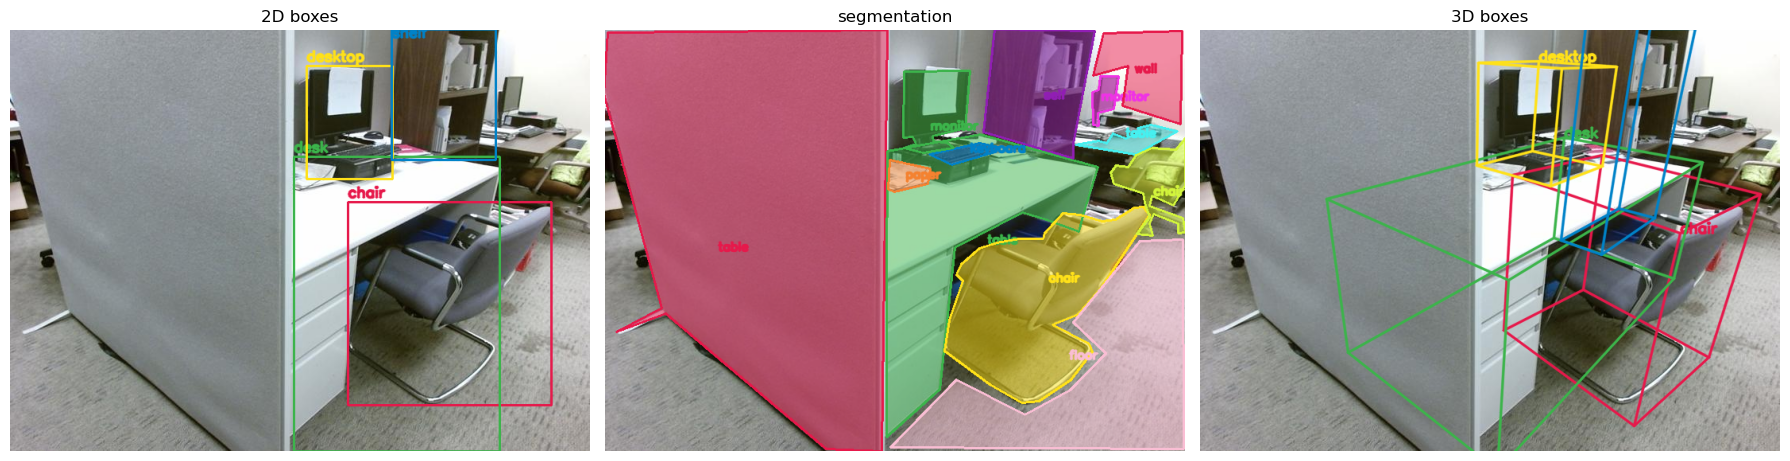

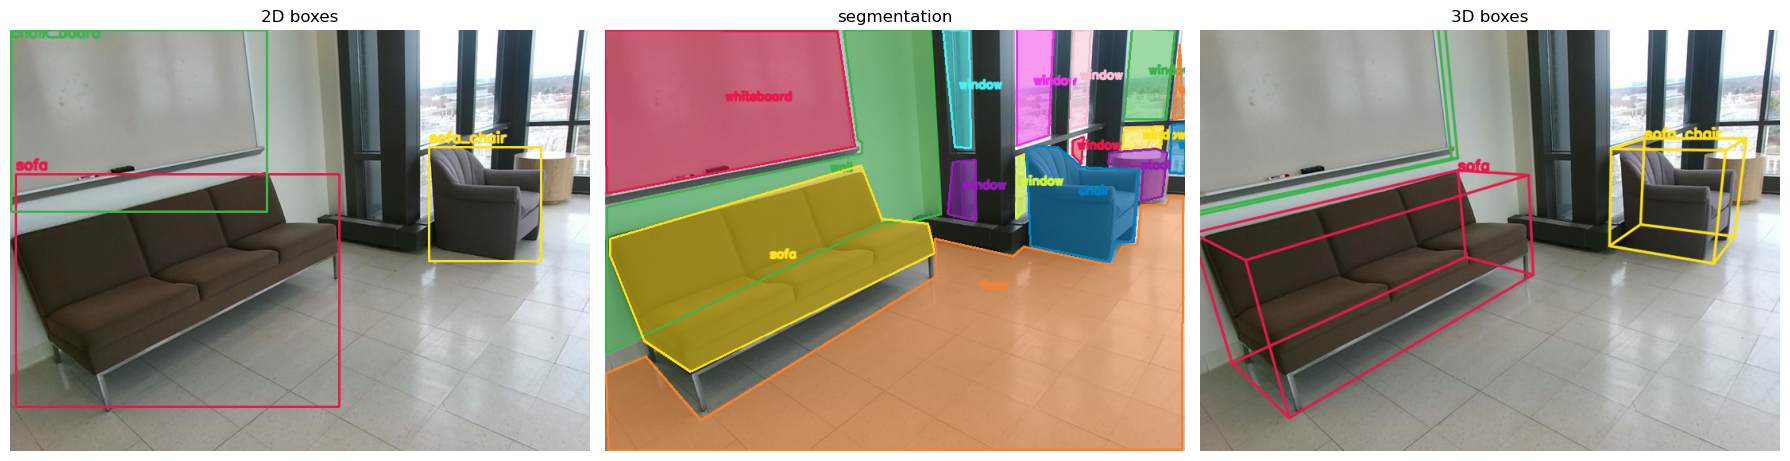

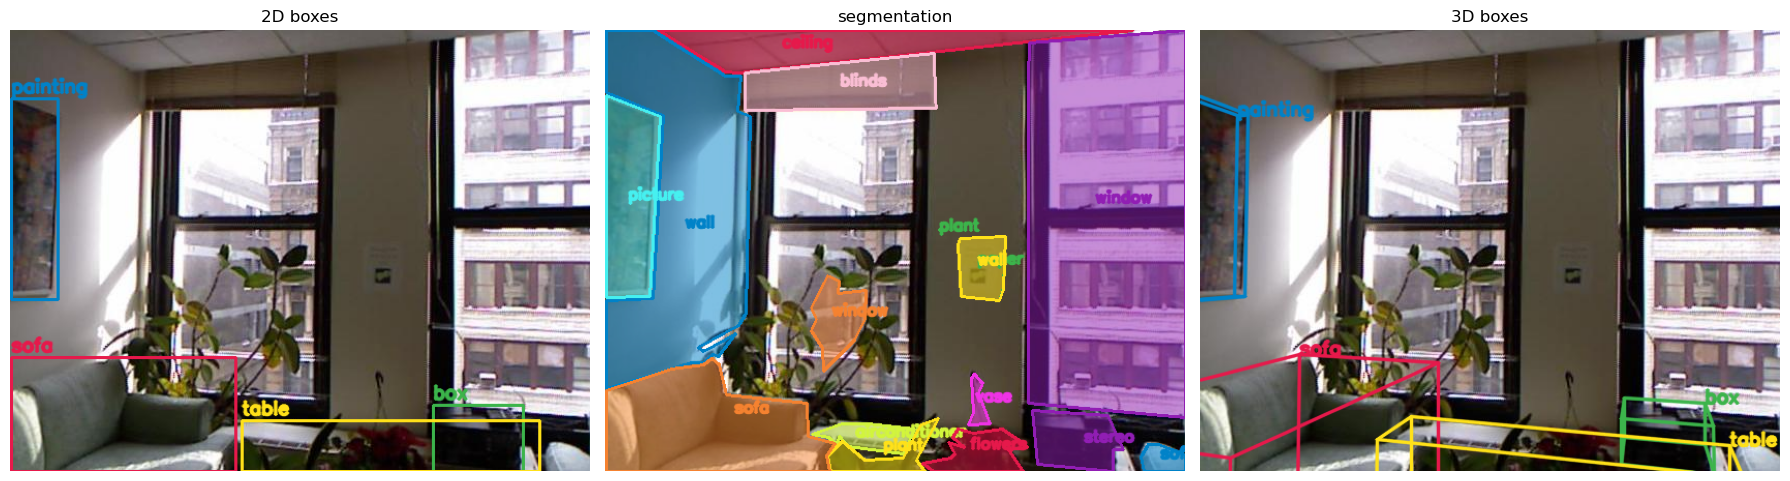

In [7]:
for image_id in [1715, 1719, 1863]:
    show_example(image_id)

## Register as a detectron2 dataset

Builds a `DatasetCatalog`/`MetadataCatalog` entry over every image with clean matched 2D/3D box ground truth
(`matched_objects`), using the union of their classnames as `thing_classes` -- SUN RGB-D's full per-object
vocabulary (hundreds of fine-grained names), not just the 10-class furniture subset some benchmarks restrict to.

In [8]:
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.structures import BoxMode
from PIL import Image


def xywh_to_xyxy(box: np.ndarray) -> list:
    x, y, w, h = np.asarray(box, dtype=float)
    return [x, y, x + w, y + h]


def sunrgbd_dataset_dicts() -> tuple[list[str], list[dict]]:
    """Every image with matched_objects, as detectron2 dicts; thing_classes is the sorted set of classnames seen."""
    records = []
    for image_id in range(len(SUNRGBDMeta)):
        matches = matched_objects(SUNRGBDMeta[image_id], SUNRGBDMeta2DBB[image_id])
        if not matches:
            continue
        e3 = SUNRGBDMeta[image_id]
        file_name = scene_dir(e3.rgbpath) / "image" / Path(e3.rgbpath).name
        if not file_name.exists():
            continue
        width, height = Image.open(file_name).size
        records.append((image_id, file_name, width, height, matches))

    classes = sorted({box_2d.classname for *_, matches in records for box_2d, _ in matches})
    class_to_id = {name: i for i, name in enumerate(classes)}
    dataset_dicts = [
        {
            "file_name": str(file_name),
            "image_id": image_id,
            "height": height,
            "width": width,
            "annotations": [
                {"bbox": xywh_to_xyxy(box_2d.gtBb2D), "bbox_mode": BoxMode.XYXY_ABS, "category_id": class_to_id[box_2d.classname]}
                for box_2d, _ in matches
            ],
        }
        for image_id, file_name, width, height, matches in records
    ]
    return classes, dataset_dicts


SUNRGBD_CLASSES, _sunrgbd_dataset_dicts = sunrgbd_dataset_dicts()
if "sunrgbd" not in DatasetCatalog:
    DatasetCatalog.register("sunrgbd", lambda: _sunrgbd_dataset_dicts)
    MetadataCatalog.get("sunrgbd").set(thing_classes=SUNRGBD_CLASSES)

print(len(DatasetCatalog.get("sunrgbd")), len(SUNRGBD_CLASSES))
print(sorted(SUNRGBD_CLASSES)[:100])

8625 840
['adaptor', 'addingmachine', 'air_conditioner', 'airconditioner', 'airfan', 'alarm', 'apparatus', 'apple', 'apron', 'armoire', 'art', 'art_board', 'artificial_plant', 'ashtray', 'assorted_boxes', 'atm_machine', 'attachecase', 'avr', 'baby_bed', 'baby_chair', 'baby_stroller', 'back_pack', 'bag', 'bagpack', 'bags', 'ball', 'balloon', 'ballpen', 'banana', 'banner', 'bar_table', 'basin', 'basket', 'basketballhoop', 'bathmat', 'bathtub', 'battery', 'bean_bag', 'bed', 'bed_sheet', 'bedding', 'bench', 'bicycle', 'billboard', 'billiard_balls', 'billiard_table', 'bin', 'binder', 'bird_cage', 'blackboard', 'blanket', 'blender', 'blinds', 'board', 'boat', 'book', 'book_organizer', 'bookcase', 'books', 'bookshelf', 'bookstand', 'boombox', 'booth', 'bottle', 'bottle_spray', 'bottled_water', 'bottles', 'bowl', 'box', 'brick', 'briefcase', 'broadband_router', 'broom', 'brush', 'brush_pot', 'bucket', 'buffettable', 'bulb', 'bulletin', 'bulletin_board', 'bulletinboard', 'bunk_bed', 'bust', 'ca

## Merge semantic synonyms (pre-count)

String-level normalization only (lowercase, flatten `_`/`-`/whitespace, strip a naive trailing plural) -- catches
spelling variants like `chair`/`chairs` or `bag`/`bags`, not different-looking synonyms like `couch`/`sofa`. Applied
before counting, so the histogram below is grouped, not raw.

In [9]:
from collections import defaultdict


def canonicalize(name: str) -> str:
    """Flattened, lowercased name with a naive trailing plural stripped -- merges 'bag'/'bags' without touching
    words that already end in 's' (e.g. 'glass')."""
    normalized = " ".join(name.lower().replace("_", " ").replace("-", " ").split())
    return normalized[:-1] if normalized.endswith("s") and not normalized.endswith("ss") else normalized


def merge_synonym_counts(raw_counts: dict[str, int]) -> tuple[dict[str, int], list[list[str]]]:
    """Groups raw_counts' keys by canonicalize(), keeping the most frequent raw spelling per group as its
    representative and summing the group's counts under it. merged_groups lists only groups with more than
    one raw spelling, for auditing."""
    groups = defaultdict(list)
    for name in raw_counts:
        groups[canonicalize(name)].append(name)

    merged_counts, merged_groups = {}, []
    for group in groups.values():
        representative = max(group, key=lambda name: raw_counts[name])
        merged_counts[representative] = sum(raw_counts[name] for name in group)
        if len(group) > 1:
            merged_groups.append(sorted(group, key=lambda name: -raw_counts[name]))
    return merged_counts, merged_groups

## Class frequency

Exhaustive per-class box count from the registered dataset (`_sunrgbd_dataset_dicts`), log-scale x since SUN RGB-D's
per-object vocabulary is extremely long-tailed (`chair` alone accounts for over a third of all boxes, most other
classes appear only once).

merged 60 raw classnames into 30 groups, e.g.:
  chair + chairs
  drawer + drawers
  picture + pictures
  book + books
  plant + plants
  bag + bags
  bottle + bottles
  cup + cups
  poster + posters
  shoes + shoe
  toy + toys
  container + containers
  light + lights
  pen + pens
  diploma + diplomas


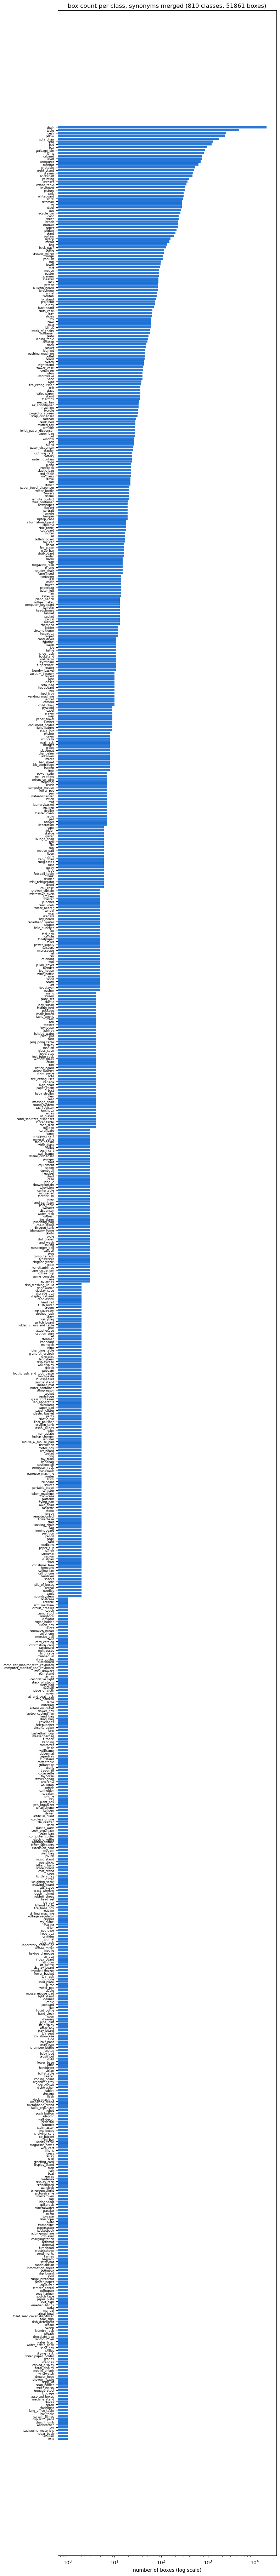

In [10]:
from collections import Counter

box_counts = Counter(ann["category_id"] for record in _sunrgbd_dataset_dicts for ann in record["annotations"])
raw_counts = {SUNRGBD_CLASSES[i]: n for i, n in box_counts.items()}
merged_counts, merged_groups = merge_synonym_counts(raw_counts)
print(f"merged {sum(len(g) for g in merged_groups)} raw classnames into {len(merged_groups)} groups, e.g.:")
for group in sorted(merged_groups, key=lambda g: -sum(raw_counts[n] for n in g))[:15]:
    print(" ", " + ".join(group))

counts_sorted = sorted(merged_counts.items(), key=lambda x: -x[1])
names, counts = zip(*counts_sorted)

fig, ax = plt.subplots(figsize=(8, max(6, len(names) * 0.09)))
ax.barh(range(len(names)), counts, color="#2a78d6")
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=6)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("number of boxes (log scale)")
ax.set_title(f"box count per class, synonyms merged ({len(names)} classes, {sum(counts)} boxes)")
plt.tight_layout()
plt.show()

In [11]:
frequent_classes_sun = sorted([n for n, c in counts_sorted if c > 10])
print(len(frequent_classes_sun))
print(frequent_classes_sun)

191
['air_conditioner', 'airconditioner', 'alarm', 'armoire', 'back_pack', 'bag', 'basin', 'basket', 'bathtub', 'battery', 'bed', 'bench', 'bicycle', 'binder', 'blackboard', 'blanket', 'blinds', 'board', 'book', 'bookshelf', 'bookstand', 'bottle', 'bowl', 'box', 'bucket', 'bulletin', 'bulletin_board', 'bulletinboard', 'bunk_bed', 'cabinet', 'can', 'carpet', 'cart', 'cartoon', 'chair', 'chalkboard', 'chest', 'clock', 'clothing_rack', 'coffee_maker', 'coffee_table', 'computer', 'computer_keyboard', 'container', 'counter', 'cpu', 'crib', 'cubby', 'cup', 'cupboard', 'curtain', 'decor', 'desk', 'desktop', 'dining_table', 'diploma', 'doll', 'door', 'drawer', 'dresser', 'dresser_mirror', 'electric_fan', 'end_table', 'endtable', 'eraser', 'fan', 'faucet', 'figurine', 'fire_extinguisher', 'fire_place', 'flower_vase', 'flowers', 'fridge', 'frige', 'fume_hood', 'futon', 'garbage_bin', 'glass', 'grab_bar', 'hamper', 'hand_dryer', 'headphones', 'heater', 'helmet', 'information_board', 'island', 'ja